# Práctica 02 — Titanic: de Pandas al primer modelo predictivo
**Aprendizaje Automático · UTN FRLP · Práctica autónoma guiada**

**Objetivo:** aplicar lo visto en `TP1`, `02_librerias_python` y Penguins: cargar → explorar → visualizar → tratar faltantes → preparar variables → entrenar y evaluar.

**Dataset:** [Titanic Dataset (Kaggle, M Yasser H)](https://www.kaggle.com/datasets/yasserh/titanic-dataset)

### Cómo utilizar el notebook
- Intentá resolver cada consigna antes de consultar las pistas.
- Escribí una breve **interpretación en castellano** debajo de tus resultados.
- No hay respuestas prediseñadas en las celdas `# TU CÓDIGO`.
- Si algo falla, mirá el mensaje de error: entenderlo es parte del ejercicio.

**Recordatorio:** `Survived` es la variable objetivo (`0` = no sobrevivió, `1` = sobrevivió). No la incluyas dentro de las características de entrada (`X`).

## Etapa 0 · Preparar el entorno

Instalá `kagglehub` si hace falta (desde una terminal con tu entorno virtual activo: `pip install kagglehub pandas numpy matplotlib scikit-learn`).

El código siguiente te descarga el dataset y muestra los archivos disponibles. **No supongas el nombre del CSV:** revisá la salida.

In [1]:
from pathlib import Path
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

path = Path(kagglehub.dataset_download("yasserh/titanic-dataset"))
print("Carpeta:", path)
print("Archivos:", [f.name for f in path.iterdir()])

Carpeta: C:\Users\famil\.cache\kagglehub\datasets\yasserh\titanic-dataset\versions\1
Archivos: ['Titanic-Dataset.csv']


### 0.1 · Cargar el archivo

1. Identificá el CSV.
2. Creá un DataFrame llamado `df` usando `pd.read_csv()`.
3. Mostrá sus cinco primeras filas.

**Pista:** en el TP1 utilizaste `pd.read_csv(Path(path) / "archivo.csv")`.

In [2]:
# TU CÓDIGO
df = pd.read_csv(path / "Titanic-Dataset.csv" )
df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Etapa 1 · Reconocer el dataset (Pandas)

Respondé **con código y en texto**:
1. ¿Cuántas filas y columnas tiene `df`?
2. ¿Qué columnas tienen datos numéricos y cuáles contienen texto?
3. ¿Qué información muestra `describe()`? ¿Qué cambia si usás `describe(include="all")`?
4. ¿Qué valores toma `Survived` y cuántos hay de cada clase?
5. ¿`PassengerId` es una variable útil para explicar la supervivencia o solo identifica filas? Justificá.

**Pistas:** `.shape`, `.info()`, `.dtypes`, `.describe()`, `.value_counts()`.

In [ ]:
# TU CÓDIGO: exploración
df.shape # Dimensiones del DataFrame
df.info()
df.describe()
df.describe(include='all')
df




<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


: 

**Mis conclusiones de la Etapa 1**

- Tiene 891 filas y 12 columnas.
- 7 columnas tienen datos numéricos (`PassengerId`, `Survived` (clasificación binaria), `Pclass` (categórica ordinal), `Age`, `SibSp`, `Parch` y `Fare`) y el resto contienen texto / son alfanuméricas (`Name`, `Sex`, `Ticket`, `Cabin`, `Embarked`).
- `describe()` genera un resumen estadístico solo de las columnas numéricas: cantidad de valores no nulos (`count`), promedio (`mean`), desviación estándar (`std`), el **valor mínimo** (`min`) y el **valor máximo** (`max`) de la columna, y los cuartiles (25%, 50%/mediana y 75%) que dividen los datos ordenados en percentiles. En cambio `describe(include='all')` fuerza a incluir también las columnas alfanuméricas, agregando `unique` (cantidad de valores distintos), `top` (el valor que más se repite, la moda) y `freq` (cuántas veces aparece ese valor top).
- `Survived` toma solo dos valores: 0 (no sobrevivió) o 1 (sobrevivió).
- `PassengerId` no es útil para explicar la supervivencia: es solo un identificador único de cada fila (un número correlativo), no aporta información sobre el pasajero, por eso no se incluye en `X`.

## Etapa 2 · Valores faltantes

1. Calculá cuántos valores `NaN` tiene cada columna.
2. Calculá el **porcentaje** de faltantes por columna, respecto de las filas.
3. Ordená esos porcentajes de mayor a menor.
4. ¿Qué columnas considerarías imputar? ¿Descartarías alguna? Explicá por qué.
5. Pensá por qué `Age` y `Embarked` podrían necesitar estrategias distintas de imputación.

**Pistas:** `.isna()`, `.sum()`, `len(df)`, `.sort_values(ascending=False)`.

⚠️ **Importante:** todavía no modifiques `df`: primero analizá las alternativas.

In [4]:
# TU CÓDIGO: faltantes y porcentajes
 # Cantidad de valores faltantes por columna
porcentajes = df.isna().mean() * 100 # Porcentaje de valores faltantes por columna
porcentajes.sort_values(ascending=False)
df.isna().sum()



PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

**Decisiones sobre los faltantes**

- Deberia imputar los valores Age, Embarked y Cabin ya que existen valores faltantes podria descartar del modelo la columna Cabin ya que faltan demasiado datos
- Para Age podria utilizar la media o la mediana ya que si bien faltan datos serviria como una primera iteracion y luego para Embarked utilizaria la moda ya que solo faltan dos valores

## Etapa 3 · Explorar relaciones (EDA)

1. Calculá el porcentaje de supervivencia total.
2. Calculá el porcentaje de supervivencia por `Sex`.
3. Calculá el porcentaje de supervivencia por `Pclass`.
4. Calculá la edad promedio y la mediana por `Survived`.
5. Compará el precio promedio del pasaje de quienes sobrevivieron y quienes no.
6. Filtrá los pasajeros menores de 18 años y observá cuántos sobrevivieron.

**Pistas:** `groupby(...)[...].mean()`, máscaras booleanas, `.median()`.

**Pregunta de interpretación:** ¿un patrón encontrado en estos datos demuestra causalidad?

In [5]:
# TU CÓDIGO: groupby y filtros
# Porcentaje de superviencia total
df['Survived'].value_counts(normalize=True) * 100 # El normalize=True devuelve proporciones en lugar de conteos absolutos
# Porcentaje de superviencia por sexo
df.groupby('Sex')['Survived'].value_counts(normalize=True) * 100
# Si quisiera solo ver los que sobrevieron por sexo, puedo filtrar el DataFrame
df.groupby('Sex')['Survived'].value_counts(normalize=True).loc[:, 1] * 100 # El loc[:, 1] filtra el DataFrame para mostrar solo la columna correspondiente a los que sobrevivieron (Survived = 1)
# Porcentaje de superviencia por clase
df.groupby('Pclass')['Survived'].value_counts(normalize=True) * 100
# La edad promedio y mediana de los sobrevivientes y no sobrevivientes
df.groupby('Survived')['Age'].agg(['mean', 'median']) # agg permite aplicar múltiples funciones de agregación a la vez, en este caso 'mean' y 'median' para calcular la media y mediana de la edad de los sobrevivientes y no sobrevivientes.
# Comparacion del precio de tickets entre sobrevivientes y no sobrevivientes
df.groupby('Survived')['Fare'].agg(['mean', 'median']) 
# Pasajeron menores a 18 años y su porcentaje de supervivencia
df[df['Age'] < 18].groupby('Survived')['Age'].count() / df[df['Age'] < 18].shape[0] * 100 # El count() devuelve el número de pasajeros menores a 18 años que sobrevivieron y no sobrevivieron. Para obtener el porcentaje de supervivencia, podemos dividir el número de sobrevivientes entre el total de pasajeros menores a 18 años y multiplicar por 100.

Survived
0    46.017699
1    53.982301
Name: Age, dtype: float64

**Interpretación de relaciones**

- **Supervivencia total:** sobrevivió alrededor del 38% y no sobrevivió el 62%; es un dataset desbalanceado hacia los que no sobrevivieron.
- **Sexo:** las mujeres sobrevivieron muchísimo más que los hombres (~74% vs ~19%). Es la variable más determinante: refleja la política de "mujeres y niños primero".
- **Clase (`Pclass`):** a mayor clase, mayor supervivencia (1ª ≈ 63%, 2ª ≈ 47%, 3ª ≈ 24%). La clase funciona como un indicador del nivel socioeconómico y de la ubicación de los camarotes.
- **Edad y tarifa:** los sobrevivientes pagaron en promedio una **tarifa (`Fare`) más alta**, lo cual es coherente con lo anterior (tarifa alta ≈ clase alta). La edad promedio es similar entre ambos grupos, así que por sí sola no separa tanto.
- **Menores de 18:** sobrevivieron en mayor proporción que la media general, otra vez consistente con "niños primero".
- **¿Causalidad?** No. Estos patrones muestran **correlación/asociación**, no causalidad. Que las mujeres o los de 1ª clase sobrevivieran más no "demuestra" que el sexo o la clase *causen* la supervivencia de forma aislada: hay variables que se mezclan entre sí (por ejemplo clase y tarifa están relacionadas). Para hablar de causalidad harían falta un diseño experimental o técnicas específicas, no solo un `groupby`.

## Etapa 4 · Visualizaciones con Matplotlib

Creá los siguientes gráficos **por separado**, con título y etiquetas en los ejes:
1. Un **histograma** de `Age` (elegí cuántos intervalos usar).
2. Un **gráfico de barras** con el porcentaje de supervivencia por `Pclass`.
3. Un **gráfico de dispersión** `Age` versus `Fare` (identificá si observás valores atípicos).
4. **Opcional:** dos histogramas de edades: uno para quienes sobrevivieron y otro para quienes no.

**Pistas:** `fig, ax = plt.subplots()`, `ax.hist(...)`, `ax.bar(...)`, `ax.scatter(...)`, `plt.show()`.

⚠️ Los `NaN` pueden afectar algunos gráficos. Decidí cómo tratarlos de forma explícita para cada visualización.

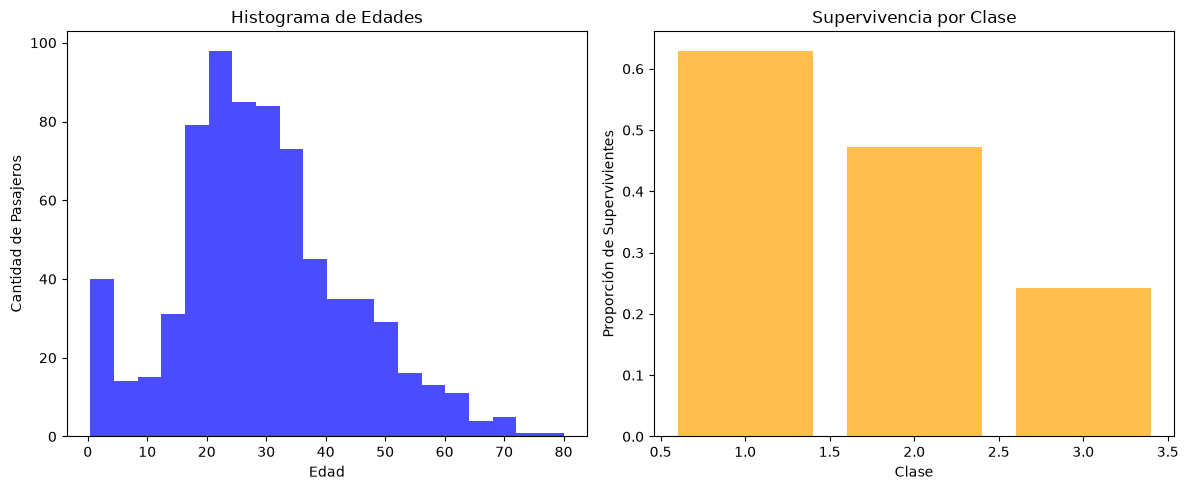

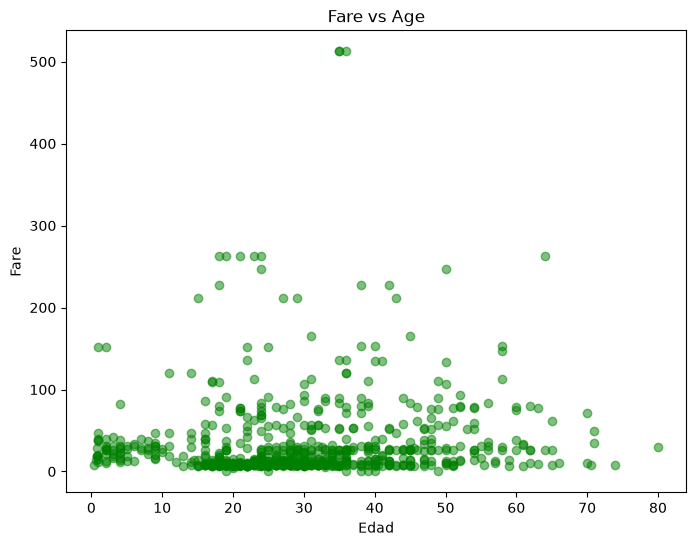

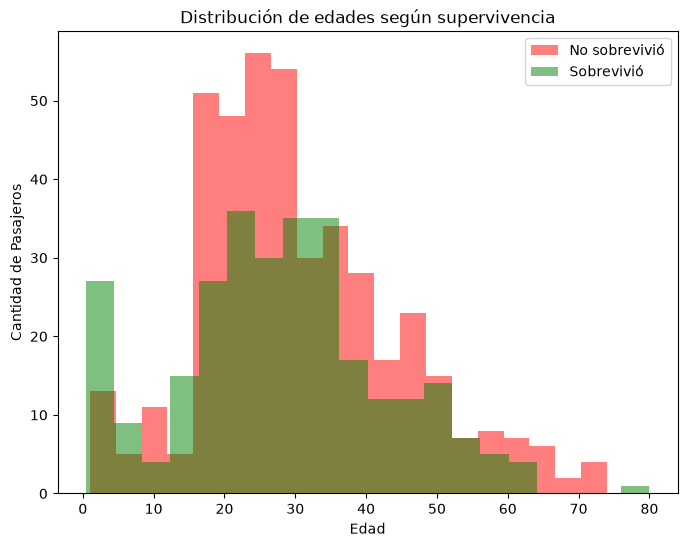

In [6]:
# TU CÓDIGO: gráficos
# 1) Histograma de edades  +  2) Barras de supervivencia por clase (uno al lado del otro)
fig, ax = plt.subplots(1, 2, figsize=(12, 5)) # 1 fila, 2 columnas, tamaño de la figura (12, 5)
ax[0].hist(df['Age'].dropna(), bins=20, color='blue', alpha=0.7) # dropna() elimina los NaN para que no afecten el histograma
ax[0].set_title('Histograma de Edades')
ax[0].set_xlabel('Edad')
ax[0].set_ylabel('Cantidad de Pasajeros')

ax[1].bar(df.groupby('Pclass')['Survived'].mean().index,
          df.groupby('Pclass')['Survived'].mean().values,
          color='orange', alpha=0.7) # mean() sobre Survived (0/1) devuelve la proporción de sobrevivientes por clase
ax[1].set_title('Supervivencia por Clase')
ax[1].set_xlabel('Clase')
ax[1].set_ylabel('Proporción de Supervivientes')
plt.tight_layout()
plt.show() # Renderiza la figura con los dos gráficos

# 3) Gráfico de dispersión Age vs Fare
plt.figure(figsize=(8, 6))
plt.scatter(df['Age'], df['Fare'], alpha=0.5, color='green') # alpha es la transparencia del color
plt.title('Fare vs Age')
plt.xlabel('Edad')
plt.ylabel('Fare')
plt.show() # Se observan algunos valores atípicos (outliers): tarifas muy altas (>500) con pocos pasajeros

# 4) Opcional: dos histogramas de edad, sobrevivientes vs no sobrevivientes, superpuestos
plt.figure(figsize=(8, 6))
plt.hist(df[df['Survived'] == 0]['Age'].dropna(), bins=20, alpha=0.5, label='No sobrevivió', color='red')
plt.hist(df[df['Survived'] == 1]['Age'].dropna(), bins=20, alpha=0.5, label='Sobrevivió', color='green')
plt.title('Distribución de edades según supervivencia')
plt.xlabel('Edad')
plt.ylabel('Cantidad de Pasajeros')
plt.legend() # Muestra la referencia de colores
plt.show()


**Interpretación de los gráficos**

- **Histograma de `Age`:** la mayoría de los pasajeros tenían entre 20 y 40 años; la distribución está algo sesgada hacia la derecha (hay más jóvenes que ancianos) y se nota un pico de niños pequeños.
- **Barras de supervivencia por `Pclass`:** se ve clarísima la pendiente: 1ª clase sobrevive mucho más que 3ª. Confirma visualmente lo que vimos con números en la Etapa 3.
- **Dispersión `Age` vs `Fare`:** la nube se concentra en tarifas bajas (<100). Hay unos pocos **outliers** con tarifas muy altas (>500) que corresponden a muy pocos pasajeros; conviene tenerlos en cuenta porque pueden distorsionar promedios.
- **Histogramas superpuestos (opcional):** en edades chicas (niños) la barra verde (sobrevivió) tiende a ser relativamente mayor, mientras que en la franja adulta joven predomina el rojo (no sobrevivió). Refuerza el patrón "niños primero".
- **NaN:** usé `dropna()` en los gráficos de `Age` para que los valores faltantes no rompieran los histogramas; fue una decisión explícita de visualización, distinta de la imputación que hago para el modelo.

## Etapa 5 · Imputación con Scikit-learn

1. Copiá el DataFrame a `df_trabajo` para no perder el original.
2. Aplicá `SimpleImputer(strategy="median")` a `Age`.
3. Aplicá `SimpleImputer(strategy="most_frequent")` a `Embarked`.
4. Verificá si los `NaN` de esas columnas desaparecieron.
5. Compará **la mediana de edades antes y después de imputar**. ¿Cambió mucho la distribución?
6. **Reto:** compará la imputación simple de `Age` con un enfoque multivariable usando únicamente columnas numéricas adecuadas.

**Pistas:** `from sklearn.impute import SimpleImputer` y `.fit_transform()`.

**Advertencia para modelado:** esta etapa es exploratoria. Cuando entrenemos un modelo, la imputación debe aprenderse solamente del conjunto de entrenamiento para evitar **fuga de datos** (*data leakage*).

In [7]:
from sklearn.impute import SimpleImputer

df_trabajo = df.copy()  # No modifiques df mientras practicás.
# Comenzamos con la imputacion de la columna Age. Para ello, vamos a crear un objeto SimpleImputer que reemplace los valores faltantes por la mediana de la columna.
imputer = SimpleImputer(strategy='median') # Creamos el objeto SimpleImputer con la estrategia de imputación 'median' para reemplazar los valores faltantes por la mediana de la columna.
df_trabajo['Age'] = imputer.fit_transform(df_trabajo[['Age']]) # Aplicamos el imputador a la columna 'Age' y reemplazamos los valores faltantes por la mediana de la columna. El fit_transform() ajusta el imputador a los datos y luego transforma los datos, devolviendo un array con los valores imputados. Como el resultado es un array, debemos usar doble corchete para mantener la forma de DataFrame y asignarlo de nuevo a la columna 'Age' del DataFrame df_trabajo.
# Ahora vamos a imputar la columna Embarked. Para ello, vamos a crear un objeto SimpleImputer que reemplace los valores faltantes por la moda de la columna.
imputer = SimpleImputer(strategy='most_frequent') # Creamos el objeto SimpleImputer con la estrategia de imputación 'most_frequent' para reemplazar los valores faltantes por la moda de la columna.
df_trabajo['Embarked'] = imputer.fit_transform(df_trabajo[['Embarked']]).ravel() # Aplicamos el imputador a la columna 'Embarked' y reemplazamos los valores faltantes por la moda de la columna. El fit_transform() ajusta el imputador a los datos y luego transforma los datos, devolviendo un array con los valores imputados. Como el resultado es un array, debemos usar doble corchete para mantener la forma de DataFrame y asignarlo de nuevo a la columna 'Embarked' del DataFrame df_trabajo. # Teniamos un error que nos daba un array de 2 dimensiones, por eso usamos ravel() para aplanarlo y que quede como un array de 1 dimensión.
# Verificamos si desaparecieron los valores faltantes en las columnas Age y Embarked.
df_trabajo.isna().sum() # El isna() devuelve un DataFrame con valores booleanos indicando si cada celda es NaN o no. Luego, el sum() devuelve la cantidad de valores faltantes por columna. Como ya imputamos las columnas 'Age' y '


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64

In [8]:
# Comparamos las medianas de las edades antes y después de la imputación para ver si hubo algún cambio significativo.
print("Mediana de edades antes de la imputación:", df['Age'].median())
print("Mediana de edades después de la imputación:", df_trabajo['Age'].median())

Mediana de edades antes de la imputación: 28.0
Mediana de edades después de la imputación: 28.0


In [9]:
# Reto: comparar la imputación SIMPLE (mediana) con una imputación ITERATIVA (multivariable).
# La imputación iterativa usa un modelo de regresión para PREDECIR el valor faltante de 'Age'
# en función de las otras columnas numéricas, en lugar de poner siempre el mismo número.
#
# IMPORTANTE: para comparar de verdad las dos estrategias hay que partir SIEMPRE del df ORIGINAL,
# que todavía tiene los NaN. Si usáramos df_trabajo (donde Age ya fue imputada), el imputador
# no tendría ningún hueco para rellenar y la comparación no diría nada.

from sklearn.experimental import enable_iterative_imputer  # necesario para habilitar IterativeImputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import LinearRegression

# a) Imputación simple (mediana) sobre el df original
age_simple = SimpleImputer(strategy='median').fit_transform(df[['Age']]).ravel()

# b) Imputación iterativa usando varias columnas numéricas como predictoras
imputer_iter = IterativeImputer(estimator=LinearRegression(), max_iter=10, random_state=0)
age_iter = imputer_iter.fit_transform(df[['Age', 'Fare', 'Pclass', 'SibSp', 'Parch']])[:, 0] # [:, 0] = columna Age

# c) Comparamos medias y medianas de cada estrategia
print("            | original (con NaN) | simple (mediana) | iterativa")
print(f"Mediana Age | {df['Age'].median():>18.2f} | {pd.Series(age_simple).median():>16.2f} | {pd.Series(age_iter).median():>9.2f}")
print(f"Media   Age | {df['Age'].mean():>18.2f} | {pd.Series(age_simple).mean():>16.2f} | {pd.Series(age_iter).mean():>9.2f}")


            | original (con NaN) | simple (mediana) | iterativa
Mediana Age |              28.00 |            28.00 |     27.54
Media   Age |              29.70 |            29.36 |     29.28


**Qué aprendí de imputación**

- **Imputar** es rellenar los valores faltantes (`NaN`) para que el modelo pueda trabajar, porque la mayoría de los algoritmos no toleran huecos.
- Elegí estrategias distintas según el tipo de dato: **mediana** para `Age` (numérica, y la mediana es robusta a outliers) y **moda / `most_frequent`** para `Embarked` (categórica, no tiene sentido un promedio de puertos).
- La mediana de `Age` **casi no cambió** al imputar (28.0 → 28.0). Tiene sentido: la mediana es resistente, y aunque metamos 177 valores iguales al centro, el centro no se mueve. La media sí se corre un poquito.
- La **imputación iterativa** (multivariable) da valores algo distintos porque predice cada edad faltante en función de `Fare`, `Pclass`, etc., en vez de poner siempre el mismo número. En este dataset la diferencia global es chica, pero es una técnica más fina cuando las variables están correlacionadas.
- Aprendí la diferencia entre imputar **para explorar** (lo de esta etapa, sobre todo el dataset) e imputar **para modelar**: en el modelo, la imputación tiene que aprenderse **solo del `X_train`** para no cometer *data leakage*. Por eso en la Etapa 6 el `SimpleImputer` va **dentro del pipeline**.

## Etapa 6 · Primer modelo de clasificación (desafío nuevo)

Hasta acá aplicaste fundamentalmente EDA. Este paso introduce entrenamiento predictivo.

**Pregunta:** ¿podemos predecir `Survived` a partir de `Pclass`, `Sex`, `Age`, `Fare`, `SibSp` y `Parch`?

Consignas:
1. Definí `y` como `Survived` y `X` con las seis características anteriores.
2. Separá los datos en entrenamiento y prueba con `train_test_split(test_size=0.2, random_state=42, stratify=y)`.
3. Pensá cómo transformar `Sex` a números **sin usar la variable objetivo**.
4. Usá un `ColumnTransformer` o `Pipeline` para imputar `Age` y codificar `Sex` dentro del entrenamiento.
5. Entrená un clasificador simple, como `LogisticRegression`.
6. Predecí sobre el conjunto de prueba y medí `accuracy`.
7. Compará con una predicción trivial: predecir siempre la clase más frecuente. ¿Tu modelo la supera?

**Conceptos nuevos:** `X`, `y`, `fit`, `predict`, `train_test_split`, codificación de categorías, `Pipeline`, `accuracy`, fuga de datos.

**No hace falta resolver esta etapa en el primer día.** Primero terminá las etapas 0–5.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# TU CÓDIGO: prepará X e y, dividí, transformá, entrená y evaluá
# NO uses Survived como una columna de X.
#
# OJO: usamos el df ORIGINAL (con NaN), NO df_trabajo. La imputación va a aprenderse
# dentro del pipeline, solo con X_train, para no cometer data leakage.
y = df['Survived']  # variable objetivo
X = df[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']]  # variables predictoras

# Dividimos en train (80%) y test (20%). random_state=42 -> reproducible.
# stratify=y mantiene la misma proporción de sobrevivientes/no en ambos conjuntos.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Pipeline para columnas CATEGÓRICAS: imputar con la moda -> codificar a 0/1 con OneHot.
# handle_unknown='ignore' evita errores si en test aparece una categoría no vista en train.
# drop='first' elimina una categoría por columna para evitar colinealidad.
cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot',  OneHotEncoder(drop='first', handle_unknown='ignore'))
])

# Pipeline para columnas NUMÉRICAS: imputar los NaN con la mediana.
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

# El ColumnTransformer reparte cada "receta" a sus columnas.
# IMPORTANTE: hay que listar TODAS las numéricas, no solo Age; si no, las demás se descartan.
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', cat_pipe, ['Sex', 'Embarked']),
        ('num', num_pipe, ['Age', 'Fare', 'Pclass', 'SibSp', 'Parch'])
    ]
)

# Pipeline final: primero limpia/transforma (prep) y después clasifica (clf).
modelo = Pipeline([
    ('prep', preprocessor),
    ('clf',  LogisticRegression(max_iter=1000, random_state=42))
])

# Entrenamos: el preprocessor aprende mediana/moda SOLO de X_train y la LogisticRegression
# ajusta su fórmula para separar sobrevivientes de no sobrevivientes.
modelo.fit(X_train, y_train)

# Predecimos sobre datos que el modelo NUNCA vio (X_test) y medimos accuracy.
y_pred = modelo.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy del modelo: {accuracy:.4f}  ({accuracy:.2%})")

# Baseline: ¿y si predijéramos siempre la clase más frecuente (nadie sobrevive)?
# El modelo solo vale la pena si le gana a esta predicción trivial.
clase_mayoritaria = y_train.value_counts(normalize=True).max()
print(f"Baseline (clase mayoritaria): {clase_mayoritaria:.4f}  ({clase_mayoritaria:.2%})")
print(f"Mejora sobre el baseline: {(accuracy - clase_mayoritaria):.2%}")


Accuracy del modelo: 0.8045  (80.45%)
Baseline (clase mayoritaria): 0.6166  (61.66%)
Mejora sobre el baseline: 18.79%


## Etapa 7 · Informe final

**1. ¿Qué aprendiste sobre el dataset que no era evidente mirando las primeras cinco filas?**
Que hay **valores faltantes** importantes que no se ven arriba: `Age` (177), `Embarked` (2) y sobre todo `Cabin` (687, casi el 77%). También que la supervivencia está **muy ligada al sexo y a la clase** (las mujeres y la 1ª clase sobrevivieron mucho más), algo que no surge de mirar 5 filas sino de agrupar y graficar todo el dataset.

**2. ¿Qué valores faltantes encontraste y por qué elegiste tus estrategias?**
- `Age`: imputé con la **mediana**, porque es numérica y la mediana es robusta a los valores extremos (outliers de edad).
- `Embarked`: imputé con la **moda (`most_frequent`)**, porque es categórica (un puerto) y solo faltaban 2 valores.
- `Cabin`: la **descarté**, porque falta el ~77% de los datos; imputarla inventaría demasiada información.

**3. ¿Qué gráficos te resultaron más informativos?**
El **gráfico de barras de supervivencia por `Pclass`** (muestra clarísima la diferencia entre clases) y los **histogramas de edad superpuestos** por supervivencia (dejan ver el efecto "niños primero"). El scatter `Age` vs `Fare` fue útil para detectar **outliers** de tarifa.

**4. ¿Qué diferencia hay entre describir datos y predecir resultados?**
**Describir** (etapas 1–4) es resumir lo que *ya pasó*: contar, promediar, graficar, encontrar patrones y correlaciones en los datos que tengo. **Predecir** (etapa 6) es usar esos patrones para estimar un valor **desconocido** en datos nuevos (si un pasajero sobrevive o no). Describir mira el pasado; predecir se arriesga sobre casos que el modelo nunca vio, y por eso se evalúa con un conjunto de prueba separado.

**5. ¿Qué resultado obtuvo tu modelo? ¿Con qué comparaste su rendimiento?**
La `LogisticRegression` obtuvo un **accuracy ≈ 80.5%** sobre el conjunto de prueba. Lo comparé con un **baseline** que predice siempre la clase mayoritaria (nadie sobrevive), que da **≈ 61.7%**. Como el modelo supera al baseline en casi **19 puntos**, confirmo que aprendió patrones reales y no solo "adivina lo más común".

**6. ¿Qué harías diferente si tuvieras más tiempo?**
- Probar otros modelos (árboles, `RandomForest`) y comparar.
- Usar **validación cruzada** en vez de una sola división train/test.
- Hacer **ingeniería de variables**: extraer el título del `Name` (Mr, Mrs, Miss…), crear tamaño de familia (`SibSp + Parch`), agrupar edades en rangos.
- Mirar más métricas además de accuracy (precision, recall, matriz de confusión), porque el dataset está desbalanceado.

---
### Checklist de autoevaluación

- [x] Puedo descargar y abrir un dataset sin depender de un nombre inventado.
- [x] Sé distinguir variable objetivo y variables predictoras.
- [x] Sé contar y comparar valores faltantes.
- [x] Puedo explicar un `groupby()` y un gráfico, no solo ejecutarlos.
- [x] Sé justificar una estrategia de imputación.
- [x] Entiendo para qué sirve separar entrenamiento y prueba.
- [x] Puedo explicar qué mide `accuracy` y sus limitaciones.

**Sugerencia de trabajo:** compartí primero las etapas 0–2 para revisar si estás interpretando bien los datos; luego avanzá al resto.